# IBM Data Science Capstone | SpaceX Falcon 9 Landing Prediction

**Independent reproducible reconstruction, not a copy of your previously completed labs.** This notebook works with the bundled **90-row compact dataset**, itself transcribed from a public version of IBM `dataset_part_2.csv`. Payload masses were rounded to the nearest whole kilogram.

Source: https://github.com/liam-stuart/Applied-Data-Science-Capstone/blob/main/dataset_part_2.csv

Scope: data exploration, simple SQL, plots, Folium, and leak-free classification.

In [1]:
import pandas as pd, numpy as np, matplotlib.pyplot as plt, sqlite3
from pathlib import Path
from sklearn.model_selection import train_test_split, StratifiedKFold, GridSearchCV
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.metrics import accuracy_score, f1_score, confusion_matrix
from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC
from sklearn.tree import DecisionTreeClassifier
from sklearn.neighbors import KNeighborsClassifier
import folium

cols=['FlightNumber','Year','PayloadMass','OrbitCode','SiteCode','Flights',
      'GridFins','Reused','Legs','Block','ReusedCount','Class']
df=pd.read_csv('spacex_model_compact.csv',header=None,names=cols)
ORBIT=['LEO','ISS','PO','GTO','ES-L1','SSO','HEO','MEO','VLEO','SO','GEO']
SITE=['CCAFS SLC 40','VAFB SLC 4E','KSC LC 39A']
df['Orbit']=df.OrbitCode.map(lambda v: ORBIT[v] if v>=0 else 'GEO')
df['LaunchSite']=df.SiteCode.map(dict(enumerate(SITE)))
print('Records:',len(df),' | Successful landings:',int(df.Class.sum()),' | Rate:',round(df.Class.mean(),3))
df.head()

Records: 90  | Successful landings: 60  | Rate: 0.667


,FlightNumber,Year,PayloadMass,OrbitCode,SiteCode,Flights,GridFins,Reused,Legs,Block,ReusedCount,Class,Orbit,LaunchSite
0,1,2010,6105,0,0,1,0,0,0,1,0,0,LEO,CCAFS SLC 40
1,2,2012,525,0,0,1,0,0,0,1,0,0,LEO,CCAFS SLC 40
2,3,2013,677,1,0,1,0,0,0,1,0,0,ISS,CCAFS SLC 40
3,4,2013,500,3,1,1,0,0,0,1,0,0,GTO,VAFB SLC 4E
4,5,2013,3170,2,0,1,0,0,0,1,0,0,PO,CCAFS SLC 40


## 1. Data quality, target distribution, and launch sites

In [2]:
print('Missing values:',df.isna().sum().sum())
print('Class counts:\n',df.Class.value_counts().sort_index())
site=df.groupby('LaunchSite').Class.agg(['size','sum','mean']).sort_values('mean')
display(site.style.format({'mean':'{:.1%}'}))

Missing values: 0
Class counts:
 Class
0    30
1    60
Name: count, dtype: int64


,size,sum,mean
LaunchSite,,,
CCAFS SLC 40,55,33,60.0%
VAFB SLC 4E,13,10,76.9%
KSC LC 39A,22,17,77.3%


## 2. EDA using SQL on the 90-row reconstructed dataset

The separate historical **101-row SQL lab dataset** used in the presentation has a different denominator and should not be conflated with this dataset.

In [3]:
cn=sqlite3.connect(':memory:')
df.to_sql('falcon9',cn,index=False)
query="""SELECT LaunchSite, COUNT(*) AS launches, SUM(Class) AS successes,
              ROUND(100.0*AVG(Class), 1) AS success_pct
       FROM falcon9 GROUP BY LaunchSite ORDER BY success_pct DESC"""
pd.read_sql_query(query,cn)

,LaunchSite,launches,successes,success_pct
0,KSC LC 39A,22,17,77.3
1,VAFB SLC 4E,13,10,76.9
2,CCAFS SLC 40,55,33,60.0


## 3. Exploratory visualizations

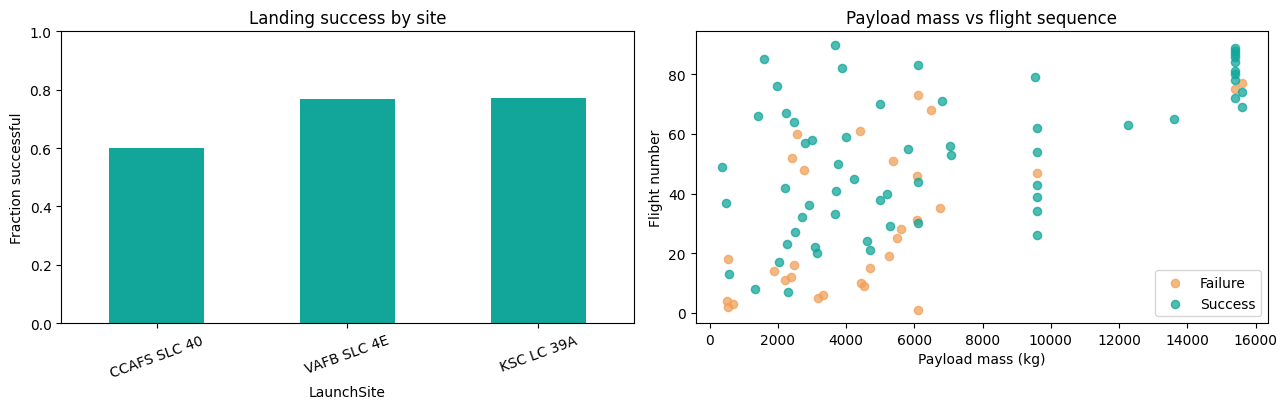

In [4]:
fig,axs=plt.subplots(1,2,figsize=(13,4.2))
site['mean'].plot.bar(ax=axs[0],color='#12A69A',ylim=(0,1),title='Landing success by site')
axs[0].set_ylabel('Fraction successful');axs[0].tick_params(axis='x',rotation=20)
for outcome,label,color in [(0,'Failure','#F1A15A'),(1,'Success','#12A69A')]:
    ss=df[df.Class==outcome]
    axs[1].scatter(ss.PayloadMass,ss.FlightNumber,s=35,alpha=.75,color=color,label=label)
axs[1].set_title('Payload mass vs flight sequence');axs[1].set_xlabel('Payload mass (kg)');axs[1].set_ylabel('Flight number');axs[1].legend()
plt.tight_layout();plt.show()

## 4. Folium interactive launch-site map

In [5]:
coordinates={'CCAFS SLC 40':(28.5618571,-80.577366),
             'VAFB SLC 4E':(34.632093,-120.610829),
             'KSC LC 39A':(28.6080585,-80.6039558)}
fm=folium.Map(location=[36,-99],zoom_start=4)
for site_name,(lat,lon) in coordinates.items():
    r=df.loc[df.LaunchSite==site_name,'Class']
    folium.CircleMarker([lat,lon],radius=8,color='green' if r.mean()>.7 else 'orange',
                        fill=True,tooltip=f'{site_name} | {r.mean():.1%} successful',
                        popup=f'{site_name}: {r.sum()}/{len(r)} successful').add_to(fm)
fm.save('Falcon9_Launch_Sites_Folium.html')
print('Saved: Falcon9_Launch_Sites_Folium.html')
fm

Saved: Falcon9_Launch_Sites_Folium.html


## 5. Predictive analysis: pipelines + stratified holdout

Preprocessing is **fitted only on training folds**. The final test set is never used for hyperparameter selection.

In [6]:
nums=['PayloadMass','Flights','GridFins','Reused','Legs','Block','ReusedCount']
cat=['Orbit','LaunchSite']
X=df[nums+cat]; y=df.Class
pre=ColumnTransformer([('num',StandardScaler(),nums),
                       ('cat',OneHotEncoder(handle_unknown='ignore'),cat)])
Xtrain,Xtest,ytrain,ytest=train_test_split(X,y,test_size=.2,stratify=y,random_state=2)
cv=StratifiedKFold(n_splits=5,shuffle=True,random_state=2)
models={
 'Logistic regression':(LogisticRegression(max_iter=2000),{'clf__C':[.1,1,10]}),
 'SVM':(SVC(),{'clf__C':[.1,1,10],'clf__gamma':['scale',.1]}),
 'Decision tree':(DecisionTreeClassifier(random_state=2),{'clf__max_depth':[2,3,4,6],'clf__min_samples_leaf':[1,3]}),
 'KNN':(KNeighborsClassifier(),{'clf__n_neighbors':[3,5,7,9],'clf__weights':['uniform','distance']})
}
results=[]; fitted={}
for name,(clf,params) in models.items():
    grid=GridSearchCV(Pipeline([('prep',pre),('clf',clf)]),params,scoring='accuracy',cv=cv,n_jobs=-1)
    grid.fit(Xtrain,ytrain)
    pred=grid.predict(Xtest)
    results.append([name,round(grid.best_score_,3),round(accuracy_score(ytest,pred),3),round(f1_score(ytest,pred),3)])
    fitted[name]=(grid,pred)
results=pd.DataFrame(results,columns=['Model','CV accuracy','Test accuracy','Test F1'])
display(results)
print('Decision tree confusion matrix:\n',confusion_matrix(ytest,fitted['Decision tree'][1]))

,Model,CV accuracy,Test accuracy,Test F1
0,Logistic regression,0.850,0.833,0.889
1,SVM,0.835,0.833,0.889
2,Decision tree,0.864,0.833,0.889
3,KNN,0.878,0.611,0.667


Decision tree confusion matrix:
 [[ 3  3]
 [ 0 12]]


## 6. Time-ordered stress test and limitations

In [7]:
earlier=df.Year<=2018
train_X,train_y=X[earlier],y[earlier]
later_X,later_y=X[~earlier],y[~earlier]
clf=DecisionTreeClassifier(random_state=2)
search=GridSearchCV(Pipeline([('prep',pre),('clf',clf)]),
                    {'clf__max_depth':[2,3,4,6],'clf__min_samples_leaf':[1,3]},
                    scoring='accuracy',cv=4)
search.fit(train_X,train_y)
yhat=search.predict(later_X)
print('Earlier train N:',len(train_y),'| later test N:',len(later_y))
print('Earlier success rate:',round(train_y.mean(),3),'| later:',round(later_y.mean(),3))
print('Later-period accuracy:',round(accuracy_score(later_y,yhat),3))
print('Note: this is a small and temporally imbalanced historical sample.');

Earlier train N: 61 | later test N: 29
Earlier success rate: 0.574 | later: 0.862
Later-period accuracy: 0.897
Note: this is a small and temporally imbalanced historical sample.


## 7. Interpretation and caveats

- Success rates vary by launch site and over time. This **does not establish causal site effects**.
- With just 18 random test observations, small differences in classification scores are unstable.
- A high later-year accuracy can partly reflect class-base-rate changes.
- Data cover 2010–2020 and should not be used as a current operational forecast.
- The interactive Dash source is supplied separately as `SpaceX_Dash.py` (requires Dash installation).